# C3 fold-in (신규 독자용 MF 점수)

MF는 학습한 독자만 독자 벡터가 있어서, 학습 때 없던 신규 독자에게는 점수를 낼 수 없습니다.
fold-in은 학습된 책 벡터·책 bias는 그대로 두고, 그 독자의 평점 몇 개만으로 독자 벡터·독자 bias를 계산합니다.

독자 한 명에 대해 Ridge regression을 풉니다(다시 학습하지 않고 식 한 번으로 구함).

- 입력 X: 책마다 [책 벡터, 1]
- 정답 y: 정답 - 전체 평균 - 책 bias
- 구하는 값: [독자 벡터, 독자 bias] = (X^T W X + fold_in_reg * I)^-1 X^T W y
- 이력의 책은 정답 = 별점, 가중치 1. 나머지 책은 학습 때와 같게 정답 0, 가중치 neg_ratio * 이력 수 / 책 수

이 노트북에서 하는 일

1. 학습에 있던 독자: 학습으로 얻은 독자 벡터와 fold-in으로 구한 독자 벡터의 추천 점수 비교
2. fold-in의 정규화 세기(`fold_in_reg`) 고르기 (cold_tune)
3. 평점 1·3·5·10개일 때의 점수를 인기순과 비교
4. 신규 독자 추천 예시

모델은 C2(추가 실험 포함)에서 고른 추천용 설정으로 `train`만 학습합니다. 학습된 모델은 `data/models/`에 저장해 두고 다른 노트북에서 다시 씁니다. 점수는 `val`과 `cold_tune`으로만 잽니다.

In [1]:
import json
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bookrec.data import load_books, load_split
from bookrec.evaluation import evaluate_cold, evaluate_warm
from bookrec.models.base import Recommender
from bookrec.models.collaborative_filtering import fit_selected_mf
from bookrec.models.collaborative_filtering.tuning import RESULT_DIR, SELECTED_PATH, TUNING_USERS, result_rows
from bookrec.models.baselines.popularity import PopularityRecommender
from bookrec.plot_style import MODEL_COLORS, save, setup

setup()
split = load_split()
started = time.time()
model = fit_selected_mf("ranking", split.train)
print(f"학습 시간 {time.time() - started:.0f}초")
model.config

학습 시간 0초


MFConfig(n_factors=128, lr=0.01, reg=0.05, n_epochs=4, batch_size=2048, neg_ratio=8, patience=2, fold_in_reg=10.0, seed=42)

## 1. 학습에 있던 독자: 학습된 독자 벡터 vs fold-in

같은 val 독자 5,000명에게 두 방식으로 추천합니다. fold-in이 학습된 독자 벡터와 비슷한 점수를 내면,
기존 독자와 신규 독자를 같은 방식(`score(이력)`)으로 처리할 수 있습니다.

In [2]:
class LearnedVectors(Recommender):
    """학습으로 얻은 독자 벡터를 그대로 쓰는 비교용 모델."""

    def __init__(self, mf):
        self.mf = mf

    def fit(self, train):
        return self

    def score(self, history):
        return self.mf.score_learned(history)


warm_learned = evaluate_warm(LearnedVectors(model), split, on="val", n_users=TUNING_USERS)
warm_fold_in = evaluate_warm(model, split, on="val", n_users=TUNING_USERS)
pd.DataFrame([warm_learned, warm_fold_in], index=["학습된 독자 벡터", f"fold-in (fold_in_reg {model.config.fold_in_reg})"]).round(4)

,precision@10,recall@10,ndcg@10,users
학습된 독자 벡터,0.0597,0.0553,0.0670,4974
fold-in (fold_in_reg 10.0),0.0629,0.0588,0.0718,4974


## 2. fold-in 정규화 세기 고르기

`fold_in_reg`가 작으면 평점 몇 개에 독자 벡터를 과하게 맞추고, 크면 독자 벡터가 0에 가까워져 모든 독자에게 비슷한 책(책 bias가 큰 책)을 추천합니다.
책 벡터는 그대로라 다시 학습하지 않고 값만 바꿔 가며 잽니다.

고르는 기준: cold_tune에서 평점 1·3·5·10개일 때 NDCG@10의 평균(네 경우 같은 비중). 기존 독자(val)의 점수도 함께 봅니다.

In [3]:
FOLD_IN_REG_VALUES = [1.0, 5.0, 10.0, 20.0, 50.0]
rows = []
for value in FOLD_IN_REG_VALUES:
    # NOTE: 설정은 바꿀 수 없는(frozen) 객체라 replace로 새 설정을 만들어 모델에 다시 넣는다. 책 벡터는 그대로다.
    model.config = replace(model.config, fold_in_reg=value)
    cold = evaluate_cold(model, split, on="tune")
    warm = evaluate_warm(model, split, on="val", n_users=TUNING_USERS)
    row = {"fold_in_reg": value, **{f"cold_ndcg@10_{size}": cold.loc[size, "ndcg@10"] for size in cold.index}}
    row["cold_mean_ndcg@10"] = cold["ndcg@10"].mean()
    row["warm_val_ndcg@10"] = warm["ndcg@10"]
    rows.append(row)
    print({key: round(item, 4) for key, item in row.items()})
fold_in_table = pd.DataFrame(rows)
fold_in_table.to_csv(RESULT_DIR / "C3_fold_in_reg.csv", index=False)
best_fold_in_reg = float(fold_in_table.loc[fold_in_table["cold_mean_ndcg@10"].idxmax(), "fold_in_reg"])
model.config = replace(model.config, fold_in_reg=best_fold_in_reg)
print(f"→ fold_in_reg = {best_fold_in_reg} 선택")
fold_in_table.round(4)

{'fold_in_reg': 1.0, 'cold_ndcg@10_1': np.float64(0.2449), 'cold_ndcg@10_3': np.float64(0.2459), 'cold_ndcg@10_5': np.float64(0.2513), 'cold_ndcg@10_10': np.float64(0.28), 'cold_mean_ndcg@10': np.float64(0.2555), 'warm_val_ndcg@10': np.float64(0.0739)}


{'fold_in_reg': 5.0, 'cold_ndcg@10_1': np.float64(0.2573), 'cold_ndcg@10_3': np.float64(0.2698), 'cold_ndcg@10_5': np.float64(0.273), 'cold_ndcg@10_10': np.float64(0.2904), 'cold_mean_ndcg@10': np.float64(0.2726), 'warm_val_ndcg@10': np.float64(0.0723)}


{'fold_in_reg': 10.0, 'cold_ndcg@10_1': np.float64(0.2529), 'cold_ndcg@10_3': np.float64(0.2709), 'cold_ndcg@10_5': np.float64(0.2784), 'cold_ndcg@10_10': np.float64(0.2956), 'cold_mean_ndcg@10': np.float64(0.2744), 'warm_val_ndcg@10': np.float64(0.0718)}


{'fold_in_reg': 20.0, 'cold_ndcg@10_1': np.float64(0.2476), 'cold_ndcg@10_3': np.float64(0.2635), 'cold_ndcg@10_5': np.float64(0.2745), 'cold_ndcg@10_10': np.float64(0.2957), 'cold_mean_ndcg@10': np.float64(0.2703), 'warm_val_ndcg@10': np.float64(0.0703)}


{'fold_in_reg': 50.0, 'cold_ndcg@10_1': np.float64(0.2413), 'cold_ndcg@10_3': np.float64(0.2529), 'cold_ndcg@10_5': np.float64(0.2621), 'cold_ndcg@10_10': np.float64(0.2792), 'cold_mean_ndcg@10': np.float64(0.2589), 'warm_val_ndcg@10': np.float64(0.0675)}
→ fold_in_reg = 10.0 선택


,fold_in_reg,cold_ndcg@10_1,cold_ndcg@10_3,cold_ndcg@10_5,cold_ndcg@10_10,cold_mean_ndcg@10,warm_val_ndcg@10
0,1.0,0.2449,0.2459,0.2513,0.2800,0.2555,0.0739
1,5.0,0.2573,0.2698,0.2730,0.2904,0.2726,0.0723
2,10.0,0.2529,0.2709,0.2784,0.2956,0.2744,0.0718
3,20.0,0.2476,0.2635,0.2745,0.2957,0.2703,0.0703
4,50.0,0.2413,0.2529,0.2621,0.2792,0.2589,0.0675


## 3. 평점이 1·3·5·10개일 때의 점수

고른 `fold_in_reg`로 cold_tune 독자 2,500명에게 추천하고 인기순과 비교합니다.
인기순은 이력을 보지 않아 네 경우의 점수가 같습니다.

In [4]:
popularity = PopularityRecommender().fit(split.train)
cold_popularity = evaluate_cold(popularity, split, on="tune")
cold_mf = evaluate_cold(model, split, on="tune")
cold_scores = pd.concat([result_rows("popularity", "cold_tune", cold_popularity), result_rows("mf_ranking", "cold_tune", cold_mf)], ignore_index=True)
cold_scores.to_csv(RESULT_DIR / "C3_cold_tune_scores.csv", index=False)
cold_scores.round(4)

,model,goal,history_size,precision@10,recall@10,ndcg@10,users
0,popularity,cold_tune,1,0.2072,0.0303,0.2213,2500
1,popularity,cold_tune,3,0.2072,0.0303,0.2213,2500
2,popularity,cold_tune,5,0.2072,0.0303,0.2213,2500
3,popularity,cold_tune,10,0.2072,0.0303,0.2213,2500
4,mf_ranking,cold_tune,1,0.2414,0.0354,0.2529,2500
5,mf_ranking,cold_tune,3,0.2596,0.0383,0.2709,2500
6,mf_ranking,cold_tune,5,0.2664,0.0395,0.2784,2500
7,mf_ranking,cold_tune,10,0.2844,0.0426,0.2956,2500


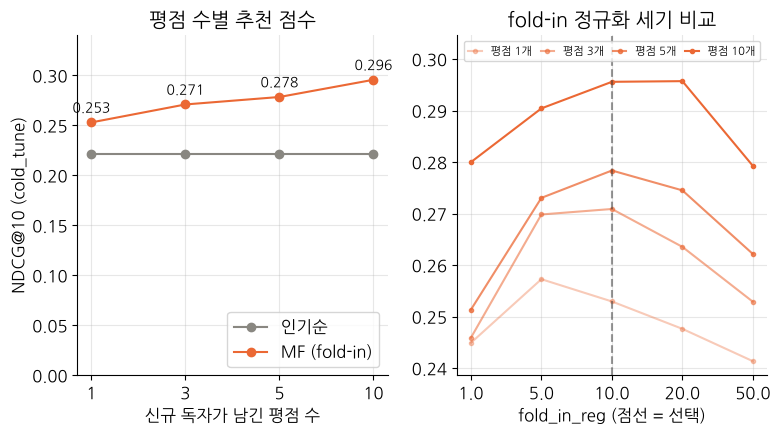

In [5]:
fig, (left, right) = plt.subplots(1, 2)
sizes = cold_mf.index.astype(str)
left.plot(sizes, cold_popularity["ndcg@10"], color=MODEL_COLORS["baseline"], marker="o", label="인기순")
left.plot(sizes, cold_mf["ndcg@10"], color=MODEL_COLORS["mf"], marker="o", label="MF (fold-in)")
for x, y in zip(sizes, cold_mf["ndcg@10"]):
    left.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=10)
left.set_xlabel("신규 독자가 남긴 평점 수")
left.set_ylabel("NDCG@10 (cold_tune)")
# NOTE: 위쪽에 여백을 둬서 숫자 표시가 제목과 겹치지 않게 한다.
left.set_ylim(0, cold_mf["ndcg@10"].max() * 1.15)
left.set_title("평점 수별 추천 점수")
left.legend(loc="lower right")
# NOTE: 평점 수(1·3·5·10)마다 선 하나씩, fold_in_reg에 따라 NDCG@10이 어떻게 바뀌는지 그린다. alpha는 선의 진하기다.
for size, alpha in zip(cold_mf.index, [0.35, 0.55, 0.75, 1.0]):
    right.plot(fold_in_table["fold_in_reg"].astype(str), fold_in_table[f"cold_ndcg@10_{size}"], color=MODEL_COLORS["mf"], alpha=alpha, marker="o", markersize=3, label=f"평점 {size}개")
right.axvline(str(best_fold_in_reg), color="#333333", linestyle="--", alpha=0.5)
right.set_xlabel("fold_in_reg (점선 = 선택)")
right.set_title("fold-in 정규화 세기 비교")
# NOTE: 범례가 선을 가리지 않도록 위쪽 여백을 조금 늘리고, 범례를 맨 위에 한 줄(ncol=4)로 둔다.
right.set_ylim(top=fold_in_table[[f"cold_ndcg@10_{size}" for size in cold_mf.index]].max().max() * 1.03)
right.legend(fontsize=8, ncol=4, loc="upper center", columnspacing=0.8, handlelength=1.2)
save(fig, "C3_fold_in_cold")
plt.show()

## 4. 신규 독자 추천 예시

학습에 없는 가상의 독자 두 명이 책 3권에 5점을 준 상황에서 MF(fold-in)가 추천하는 10권입니다.

In [6]:
books = load_books().set_index("book_id")


def find_book(title_part: str) -> int:
    """제목에 title_part가 들어간 책 중 평점 수가 가장 많은 책의 book_id."""
    # NOTE: str.contains(문자열, regex=False)는 제목에 그 문자열이 그대로 들어 있는지 본다.
    matched = books[books["title"].str.contains(title_part, regex=False)]
    return int(matched["ratings_count"].idxmax())


examples = {
    900001: ["Harry Potter and the Sorcerer's Stone", "The Hobbit", "The Lightning Thief"],
    900002: ["Pride and Prejudice", "Jane Eyre", "Wuthering Heights"],
}
example_history = pd.DataFrame(
    [(user, find_book(title), 5) for user, titles in examples.items() for title in titles], columns=["user_id", "book_id", "rating"]
)
example_recs = model.recommend(example_history, k=10)
example_rows = []
for user, titles in examples.items():
    print(f"\n고른 책: {', '.join(titles)}")
    for rank, book_id in enumerate(example_recs[user], start=1):
        print(f"  {rank:>2}. {books.loc[book_id, 'title']} ({books.loc[book_id, 'main_author']})")
        example_rows.append({"picked": " / ".join(titles), "rank": rank, "book_id": book_id, "title": books.loc[book_id, "title"], "author": books.loc[book_id, "main_author"]})
pd.DataFrame(example_rows).to_csv(RESULT_DIR / "C3_example_recommendations.csv", index=False)


고른 책: Harry Potter and the Sorcerer's Stone, The Hobbit, The Lightning Thief
   1. Harry Potter and the Order of the Phoenix (Harry Potter, #5) (J.K. Rowling)
   2. The Hunger Games (The Hunger Games, #1) (Suzanne Collins)
   3. Harry Potter and the Prisoner of Azkaban (Harry Potter, #3) (J.K. Rowling)
   4. The Fellowship of the Ring (The Lord of the Rings, #1) (J.R.R. Tolkien)
   5. Harry Potter and the Chamber of Secrets (Harry Potter, #2) (J.K. Rowling)
   6. Harry Potter and the Deathly Hallows (Harry Potter, #7) (J.K. Rowling)
   7. Harry Potter and the Goblet of Fire (Harry Potter, #4) (J.K. Rowling)
   8. To Kill a Mockingbird (Harper Lee)
   9. Harry Potter and the Half-Blood Prince (Harry Potter, #6) (J.K. Rowling)
  10. Catching Fire (The Hunger Games, #2) (Suzanne Collins)

고른 책: Pride and Prejudice, Jane Eyre, Wuthering Heights
   1. To Kill a Mockingbird (Harper Lee)
   2. Harry Potter and the Sorcerer's Stone (Harry Potter, #1) (J.K. Rowling)
   3. Sense and Sensibility

## 5. 걸리는 시간과 최종 설정 저장

In [7]:
history_10 = split.cold_tune[split.cold_tune.groupby("user_id").cumcount() < 10]
started = time.time()
model.fold_in(history_10)
print(f"신규 독자 {history_10['user_id'].nunique():,}명(평점 10개씩) fold-in: {time.time() - started:.2f}초")

saved = json.loads(SELECTED_PATH.read_text())
saved["ranking"]["config"]["fold_in_reg"] = best_fold_in_reg
saved["ranking"]["fold_in"] = {
    "criterion": "highest mean cold_tune NDCG@10 over history sizes 1,3,5,10",
    "cold_mean_ndcg@10": float(fold_in_table["cold_mean_ndcg@10"].max()),
    "candidates": FOLD_IN_REG_VALUES,
}
SELECTED_PATH.write_text(json.dumps(saved, indent=2, ensure_ascii=False) + "\n")
saved["ranking"]

신규 독자 2,500명(평점 10개씩) fold-in: 0.41초


{'run_id': 'ranking-21',
 'optimizer': 'gradient_descent',
 'config': {'n_factors': 128,
  'lr': 0.01,
  'reg': 0.05,
  'n_epochs': 4,
  'batch_size': 2048,
  'neg_ratio': 8,
  'patience': 2,
  'fold_in_reg': 10.0,
  'seed': 42},
 'criterion': 'highest val NDCG@10 on 5000 val users (seed 42)',
 'val_rmse': 2.5358514784214132,
 'val_ndcg@10': 0.07233285800906869,
 'train_source': 'split.train',
 'final_evaluation_performed': True,
 'fold_in': {'criterion': 'highest mean cold_tune NDCG@10 over history sizes 1,3,5,10',
  'cold_mean_ndcg@10': 0.27443428146206517,
  'candidates': [1.0, 5.0, 10.0, 20.0, 50.0]}}